# File 3: Area Profiles (Auckland)

## Purpose
Describe who lives in each SA2 and what is nearby, then link that to rent and price. Answers the questions
a renter or buyer asks about an area: is it growing, is it family or retiree country, is there a community I belong to,
are there schools and buses nearby, and which areas are like this one.

## Inputs
| File | What |
|---|---|
| `data/clean/master_flagged.csv` | Master file with flags. `build_master.py` now also adds age, religion, qualifications, crowding, household type, cars, dwelling type, bedrooms and dampness from the 2023 census |
| `data/clean/rent_metrics_by_sa2.csv` | From File 2: rent growth, 3-bed house rent, rent-to-income |
| `data/amenities/schools_directory.csv`, `at_gtfs.zip` | School and bus/train/ferry stop locations |
| `data/amenities/gp_clinics_auckland.csv`, `halal_shops_auckland.csv` | GP practices and halal food places from OpenStreetMap (Geofabrik NZ extract, 17 Nov 2026, ODbL), built by `download_data.py` |
| `data/amenities/playgrounds_auckland.csv`, `parks_auckland.csv` | Public playgrounds and parks from the same OpenStreetMap extract (`download_data.py` `osm_parks()`) |
| `data/amenities/mosques_verified.csv` | The user's 14-entry mosque list checked entry by entry (18 Nov 2026): street address from the operator or a directory, map point from the OpenStreetMap building. 6 verified and counted; 8 unverified or duplicate, kept with a note, not counted |

## Things to keep in mind
- **Census counts are randomly rounded to base 3** by Stats NZ, so percentages in small SA2s jump around. Rankings use `analysis_ready` SA2s only.
- **Religion and ethnicity are multi-response**: one person can count in several groups, so shares can add to more than 100%.
- **The census is from March 2023.** Population and mix have moved since, most of all in new subdivisions.

## Steps
1. Load and join, check coverage of the new census columns
2. Population change 2018 → 2023
3. Life stage and housing
4. Communities: ethnicity and religion
5. Amenities: schools, mosques, GPs, halal food, playgrounds, parks and public transport
6. What goes with rent and price
7. Area types (clustering)
8. Example screen: a family shortlist
9. Save outputs

## Outputs
- `data/clean/area_profiles_by_sa2.csv`: one row per SA2 with census profile, amenity counts and area type
- `visualizations/03_*.png`

In [1]:
# STEP 0: SETUP
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter

CLEAN = Path('data/clean')
VIZ = Path('visualizations'); VIZ.mkdir(exist_ok=True)

# Palette: categorical slots 1-2, single-hue sequential, orange-grey-blue diverging
BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#b9b8b3', '#0b0b0b', '#52514e'
SEQ = 'Blues'
DIV = LinearSegmentedColormap.from_list('div', [ORANGE, '#e6e5e1', BLUE])
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GREY, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': '#ecebe8', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10,
})
dollars = FuncFormatter(lambda v, _: f'${v/1e6:.1f}m' if v >= 1e6 else f'${v/1e3:.0f}k')
CV_TICKS = [1e5, 3e5, 5e5, 1e6, 2e6, 5e6, 1e7, 3e7]

def cv_axis(ax, lo, hi):
    ax.set_xscale('log'); ax.set_xticks([t for t in CV_TICKS if lo <= t <= hi])
    ax.xaxis.set_major_formatter(dollars); ax.xaxis.set_minor_formatter(NullFormatter())
pd.set_option('display.width', 160, 'display.max_columns', 40)

### Step 1: Load and join

In [2]:
# STEP 1: LOAD AND JOIN
m = pd.read_csv(CLEAN / 'master_flagged.csv')
rent = pd.read_csv(CLEAN / 'rent_metrics_by_sa2.csv')
m = m.merge(rent[['sa2_code', 'rent_change_10y_pct', 'rent_3bed_house', 'rent_to_income_pct']], on='sa2_code', how='left')
geo = gpd.read_file('data/boundaries/auckland_sa2_2023.geojson')
geo['sa2_code'] = geo['SA22023_V1_00'].astype(int)
assert len(m) == 633 and m.sa2_code.is_unique

census = ['pop_change_2018_2023_pct', 'pct_under_15', 'pct_65_plus', 'pct_no_religion', 'pct_christian', 'pct_muslim',
          'pct_hindu', 'pct_buddhist', 'pct_bachelor_plus', 'pct_crowded', 'pct_family_households', 'pct_one_person',
          'pct_no_vehicle', 'pct_separate_house', 'avg_bedrooms', 'pct_damp']
ready = m[m.analysis_ready]
print(f'New census columns: {len(census)} | analysis-ready SA2s: {len(ready)}')
print('Missing values among analysis-ready SA2s:', ready[census].isna().sum().sum())
ready[census].describe(percentiles=[.1, .5, .9]).T[['min', '10%', '50%', '90%', 'max']].round(1)

New census columns: 16 | analysis-ready SA2s: 599
Missing values among analysis-ready SA2s: 1


,min,10%,50%,90%,max
pop_change_2018_2023_pct,-30.4,-5.4,1.2,20.4,7416.7
pct_under_15,2.2,13.8,19.0,24.6,29.5
pct_65_plus,1.8,7.1,12.3,21.8,44.2
pct_no_religion,13.7,24.3,48.5,62.3,73.0
pct_christian,14.4,24.2,32.8,45.1,69.8
pct_muslim,0.0,0.3,2.2,5.9,19.1
pct_hindu,0.0,0.7,3.7,12.6,28.6
pct_buddhist,0.0,0.5,1.6,3.3,13.2
pct_bachelor_plus,5.5,15.9,32.4,49.4,63.5
pct_crowded,0.0,2.5,6.6,20.9,41.6


### Step 2: Population change 2018 → 2023

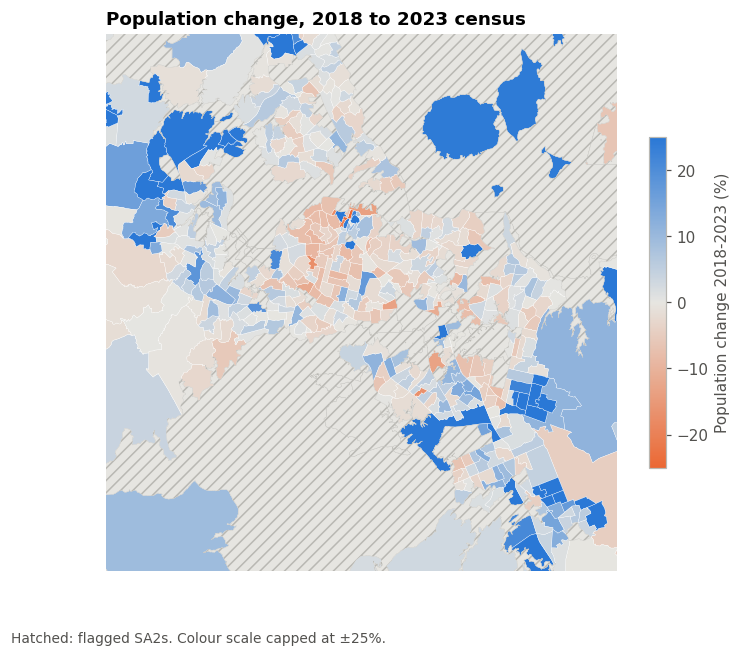

Auckland: 1,571,712 -> 1,656,417 (+5.4%)
SA2s that grew more than 25%: 50 | that shrank: 243


,sa2_name,population_2018,population_2023,pop_change_2018_2023_pct,median_rent_weekly
349,Millwater North,18.0,1353.0,7416.7,746.2
607,Donegal Park East,33.0,2247.0,6709.1,660.0
182,Orewa West,21.0,810.0,3757.1,778.2
208,Hobsonville Scott Point,123.0,3156.0,2465.8,680.0
188,Bremner Ridge,96.0,2385.0,2384.4,643.2
169,Ormiston South East,45.0,1008.0,2140.0,643.2
82,Milldale,147.0,2238.0,1422.4,830.0
415,Takanini South East,264.0,2397.0,808.0,669.5
114,Drury West,156.0,891.0,471.2,690.0
320,Pukekohe South West,633.0,2907.0,359.2,626.2


In [3]:
# STEP 2: POPULATION CHANGE (census night 2018 to census night 2023)
gm = geo[['sa2_code', 'geometry']].merge(m, on='sa2_code')
ok = gm[gm.analysis_ready]; bad = gm[~gm.analysis_ready]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ok.plot(column='pop_change_2018_2023_pct', cmap=DIV, vmin=-25, vmax=25, ax=ax, edgecolor='white', linewidth=0.2,
        legend=True, legend_kwds={'label': 'Population change 2018-2023 (%)', 'shrink': 0.6})
bad.plot(ax=ax, color='#e6e5e1', hatch='///', edgecolor=GREY, linewidth=0.2)
ax.set_title('Population change, 2018 to 2023 census'); ax.set_axis_off(); ax.set_xlim(174.55, 175.0); ax.set_ylim(-37.1, -36.72)
fig.text(0.01, 0.02, 'Hatched: flagged SA2s. Colour scale capped at ±25%.', color=MUTED, fontsize=9)
fig.savefig(VIZ / '03_population_change.png'); plt.show()

total = m[['population_2018', 'population_2023']].sum()
print(f'Auckland: {total.population_2018:,.0f} -> {total.population_2023:,.0f} ({100*(total.population_2023/total.population_2018-1):+.1f}%)')
print(f'SA2s that grew more than 25%: {(ready.pop_change_2018_2023_pct > 25).sum()} | that shrank: {(ready.pop_change_2018_2023_pct < 0).sum()}')
c = ['sa2_name', 'population_2018', 'population_2023', 'pop_change_2018_2023_pct', 'median_rent_weekly']
pd.concat([ready.nlargest(10, 'pop_change_2018_2023_pct')[c], ready.nsmallest(5, 'pop_change_2018_2023_pct')[c]]).round(1)

**Reading this:** Auckland grew 5.4%, but 243 of 599 SA2s shrank. Growth went to new subdivisions on the edge
(Millwater, Milldale, Hobsonville, Flat Bush, Takanini, Drury), which is where the very large percentages come from:
they started from almost nobody in 2018. Inner-city apartment SA2s (Hobson Ridge, Queen Street) lost 20–30%, because
the 2023 census came soon after the border reopened, when international students and migrants were few.

### Step 3: Life stage and housing

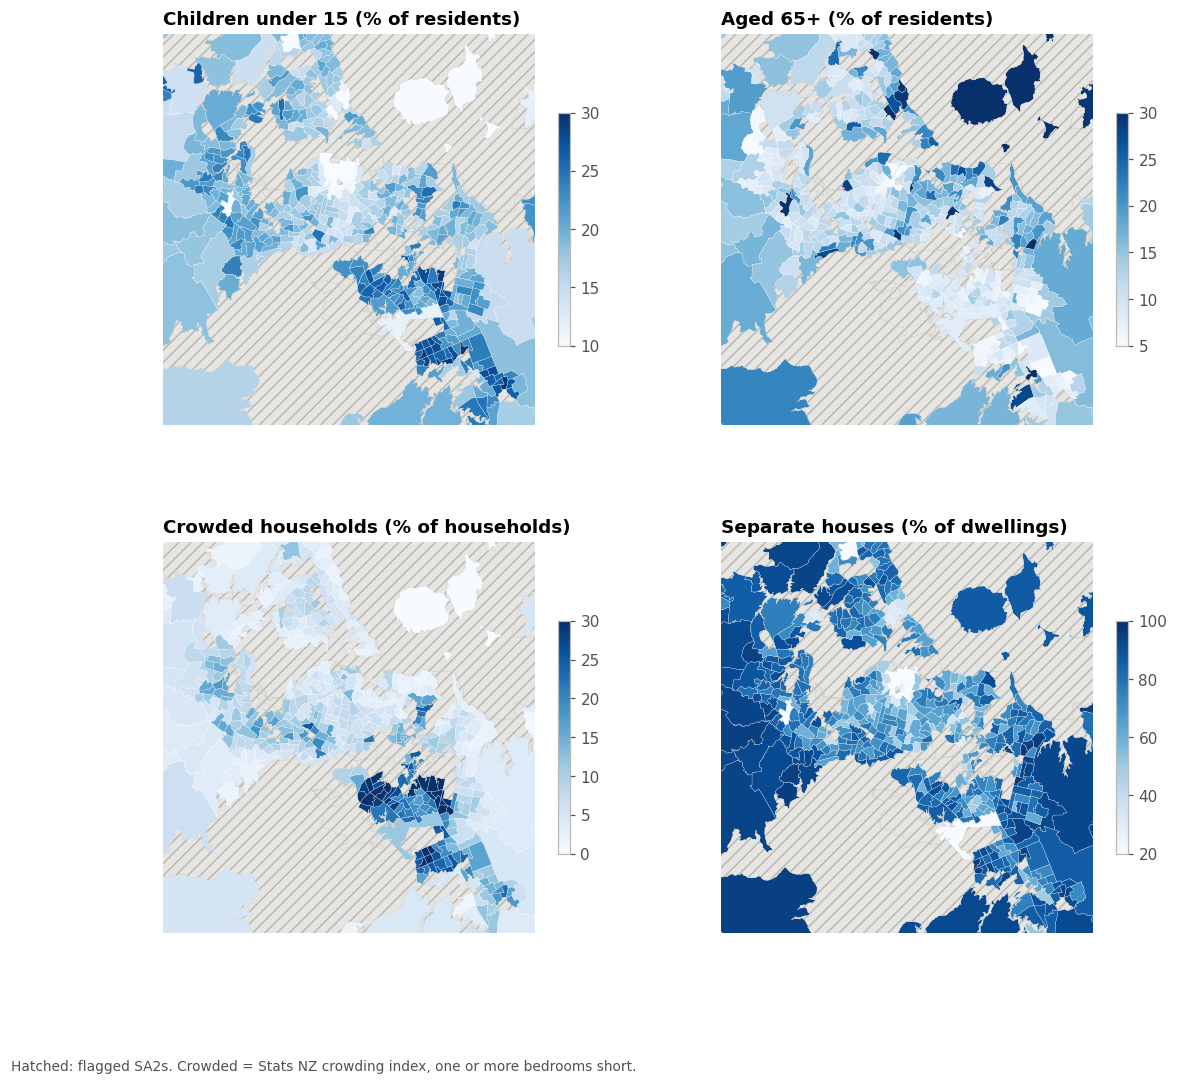

pct_under_15             19.3
pct_65_plus              13.2
pct_crowded               9.8
pct_family_households    77.1
pct_one_person           17.2
pct_separate_house       74.0
pct_no_vehicle            6.3
pct_damp                 21.1


In [4]:
# STEP 3: LIFE STAGE AND HOUSING (four maps, each with its own single-hue scale)
panels = [('pct_under_15', 'Children under 15 (% of residents)', 10, 30),
          ('pct_65_plus', 'Aged 65+ (% of residents)', 5, 30),
          ('pct_crowded', 'Crowded households (% of households)', 0, 30),
          ('pct_separate_house', 'Separate houses (% of dwellings)', 20, 100)]
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for ax, (col, title, lo, hi) in zip(axes.flat, panels):
    ok.plot(column=col, cmap=SEQ, vmin=lo, vmax=hi, ax=ax, edgecolor='white', linewidth=0.15,
            legend=True, legend_kwds={'shrink': 0.55})
    bad.plot(ax=ax, color='#e6e5e1', hatch='///', edgecolor=GREY, linewidth=0.15)
    ax.set_title(title); ax.set_axis_off(); ax.set_xlim(174.55, 175.0); ax.set_ylim(-37.1, -36.72)
fig.text(0.01, 0.01, 'Hatched: flagged SA2s. Crowded = Stats NZ crowding index, one or more bedrooms short.', color=MUTED, fontsize=9)
fig.savefig(VIZ / '03_life_stage_maps.png'); plt.show()

# Auckland-wide shares, weighted by each SA2's population
def wavg(col, d=None):
    d = ready if d is None else d
    d = d.dropna(subset=[col])
    return np.average(d[col], weights=d.population_2023)
print(pd.Series({c: wavg(c) for c in ['pct_under_15', 'pct_65_plus', 'pct_crowded', 'pct_family_households',
                                       'pct_one_person', 'pct_separate_house', 'pct_no_vehicle', 'pct_damp']}).round(1).to_string())

### Step 4: Communities, ethnicity and religion

In [5]:
# STEP 4: COMMUNITIES. Where each group is most concentrated (analysis-ready SA2s with 500+ residents,
# so small-area rounding can't put an SA2 at the top)
groups = {'pct_european': 'European', 'pct_maori': 'Māori', 'pct_pacific': 'Pacific', 'pct_asian': 'Asian',
          'pct_christian': 'Christian', 'pct_muslim': 'Muslim', 'pct_hindu': 'Hindu', 'pct_buddhist': 'Buddhist',
          'pct_no_religion': 'No religion'}
big = ready[ready.population_2023 >= 500]
rows = []
for col, label in groups.items():
    top = big.nlargest(5, col)
    rows.append({'Group': label, 'Auckland %': round(wavg(col), 1),
                 'SA2s at 2x Auckland share': int((big[col] > 2 * wavg(col)).sum()),
                 'Highest-share SA2s': ', '.join(f'{n} ({v:.0f}%)' for n, v in zip(top.sa2_name, top[col]))})
pd.set_option('display.max_colwidth', 120)
pd.DataFrame(rows).set_index('Group')

,Auckland %,SA2s at 2x Auckland share,Highest-share SA2s
Group,,,
European,49.9,0,"Tawharanui Peninsula (96%), Muriwai Valley-Bethells Beach (95%), Muriwai (95%), Sandspit (95%), Waikoukou Valley (95%)"
Māori,12.2,43,"Papakura Eastburn (49%), Red Hill (42%), Papakura Massey Park (38%), Pukekohe North West (38%), Papakura Kelvin (38%)"
Pacific,16.6,82,"Harania North (84%), Ferguson (82%), Ōtara East (80%), Sutton Park (80%), Ōtara South West (80%)"
Asian,31.3,30,"Donegal Park East (89%), Ormiston East (83%), Ormiston South (82%), Ormiston Central (80%), Pinehill South (79%)"
Christian,34.9,0,"Sutton Park (70%), Harania North (69%), Ōtara South West (69%), Ferguson (68%), Māngere West (68%)"
Muslim,2.9,61,"Wesley West (19%), Māngere South (19%), Mount Roskill Central South (18%), Māngere South East (14%), New Windsor Eas..."
Hindu,5.5,79,"Mount Roskill Nirvana (29%), Lynfield Central (25%), Mount Roskill White Swan (23%), Puhinui North (23%), Mount Rosk..."
Buddhist,1.9,41,"Donegal Park East (10%), Ormiston East (7%), Ormiston South (7%), Ormiston Central (6%), Ormiston North (6%)"
No religion,44.8,0,"Muriwai Valley-Bethells Beach (73%), Muriwai (73%), Waitākere Ranges South (72%), Piha (71%), Waima-Woodlands Park (..."


**Reading this:** a community's presence is about absolute numbers as well as share. The dashboard should show both
the % and the head count (share × population) so a large SA2 with a moderate share isn't overlooked.
Census shares show where people live, not where facilities are. The only facility measures are the two Islamic schools and the
user-supplied mosque list (Step 5); halal shops, churches, temples and community centres are not in this data.

### Step 5: Amenities, schools, mosques and public transport nearby

In [6]:
# STEP 5: AMENITIES. Counted around each SA2's centre point, not inside its boundary, because a school or stop
# just over the line still serves the area. NZTM (EPSG:2193) is in metres, so buffers are true distances.
import zipfile
centre = gpd.GeoDataFrame(geo[['sa2_code']], geometry=geo.representative_point(), crs=geo.crs).to_crs(2193)

s = pd.read_csv('data/amenities/schools_directory.csv', usecols=['Org_Name', 'Org_Type', 'Authority', 'Enrolment_Scheme',
                                                                  'Regional_Council', 'Status', 'Latitude', 'Longitude'])
s = s[(s.Regional_Council == 'Auckland Region') & (s.Status == 'Open')].dropna(subset=['Latitude', 'Longitude'])
# Year levels each MoE school type serves (15 = MoE's top level). A school counts wherever it serves: a composite (Years 1-15)
# is both primary and secondary. Specialist schools, teen parent units and activity centres are left out.
YEARS = {'Contributing': (1, 6), 'Full Primary': (1, 8), 'Intermediate': (7, 8), 'Composite': (1, 15),
         'Restricted Composite (Year 7-10)': (7, 10), 'Secondary (Year 7-10)': (7, 10), 'Secondary (Year 7-15)': (7, 15),
         'Secondary (Year 9-15)': (9, 15), 'Secondary (Year 11-15)': (11, 15)}
s = s[s.Org_Type.isin(YEARS)].copy()
s['year_from'], s['year_to'] = s.Org_Type.map(YEARS).str[0], s.Org_Type.map(YEARS).str[1]
s['serves_primary'] = s.year_from <= 8      # any of Years 1-8
s['serves_secondary'] = s.year_to >= 9      # any of Years 9-13
s['serves_year1'] = s.year_from == 1
schools = gpd.GeoDataFrame(s, geometry=gpd.points_from_xy(s.Longitude, s.Latitude), crs=4326).to_crs(2193)

with zipfile.ZipFile('data/amenities/at_gtfs.zip').open('stops.txt') as f:
    st = pd.read_csv(f, usecols=['stop_lat', 'stop_lon', 'location_type'])
st = st[st.location_type != 1]   # 1 = parent station, which would double count its platforms (same as build_master.py)
stops = gpd.GeoDataFrame(st, geometry=gpd.points_from_xy(st.stop_lon, st.stop_lat), crs=4326).to_crs(2193)

def count_within(points, metres, name):
    hits = gpd.sjoin(points, gpd.GeoDataFrame(centre[['sa2_code']], geometry=centre.buffer(metres)), predicate='within')
    return hits.groupby('sa2_code').size().rename(name)

am = pd.concat([count_within(schools[schools.serves_primary], 2000, 'primary_schools_2km'),
                count_within(schools[schools.serves_secondary], 3000, 'secondary_schools_3km'),
                count_within(stops, 800, 'pt_stops_800m')], axis=1)
m = m.join(am, on='sa2_code')
m[am.columns] = m[am.columns].fillna(0).astype(int)
# Distance from the SA2 centre to each Islamic school, kept apart because they serve different children. The directory has no
# religion field, so the schools are named: Al-Madinah School (544, composite, co-educational) and Zayed College for Girls
# (471, secondary Year 7-15, girls only). Both are State Integrated, on Westney Road, Māngere.
# shortcut: only schools in the MoE directory; weekend madrasas and ECE centres are not covered (needs another source)
isl = pd.read_csv('data/amenities/schools_directory.csv', usecols=['School_Id', 'CoEd_Status', 'Status', 'Latitude', 'Longitude'])
isl = isl[isl.School_Id.isin([471, 544]) & (isl.Status == 'Open')].set_index('School_Id')
assert isl.loc[544, 'CoEd_Status'] == 'Co-Educational' and isl.loc[471, 'CoEd_Status'] == 'Girls School'
isl = gpd.GeoDataFrame(isl, geometry=gpd.points_from_xy(isl.Longitude, isl.Latitude), crs=4326).to_crs(2193)
pts = centre.set_index('sa2_code').geometry
for sid, col in [(544, 'km_to_al_madinah_coed'), (471, 'km_to_zayed_college_girls')]:
    m[col] = m.sa2_code.map(pts.distance(isl.geometry[sid]) / 1000).round(1)
# Mosques: only entries of the user's list whose street address is confirmed by the operator or a directory AND that have a
# mapped building at that address (mosques_verified.csv, 18 Nov 2026). Unverified and duplicate entries stay in that file, not counted.
reg = pd.read_csv('data/amenities/mosques_verified.csv')
mq = reg[reg.status == 'verified']
assert mq[['name', 'lat', 'lon', 'address_source']].notna().all().all()
mosques = gpd.GeoDataFrame(mq, geometry=gpd.points_from_xy(mq.lon, mq.lat), crs=4326).to_crs(2193)
km_mq = pd.DataFrame({n: pts.distance(g) for n, g in zip(mq.name, mosques.geometry)}) / 1000   # SA2 x mosque
m['km_to_nearest_mosque'] = m.sa2_code.map(km_mq.min(axis=1)).round(1)
m['nearest_mosque'] = m.sa2_code.map(km_mq.idxmin(axis=1))

# GP practices and halal food places from OpenStreetMap (download_data.py osm_amenities). Community-mapped, so incomplete.
def pts_csv(path):
    d = pd.read_csv(path)
    return gpd.GeoDataFrame(d, geometry=gpd.points_from_xy(d.lon, d.lat), crs=4326).to_crs(2193)
gps = pts_csv('data/amenities/gp_clinics_auckland.csv')
halal = pts_csv('data/amenities/halal_shops_auckland.csv')
butchers = halal[halal.kind == 'butcher']
# Public playgrounds and parks, same extract (download_data.py osm_parks; private and customer-only sites dropped).
# Most playgrounds have no name, so they are labelled by the park they sit in.
play = pts_csv('data/amenities/playgrounds_auckland.csv')
play['label'] = play.name.fillna('Playground in ' + play.park_name).fillna('(unnamed playground)')
parks = pts_csv('data/amenities/parks_auckland.csv')
parks['label'] = parks.name.fillna('(unnamed park)')

# IN THE AREA: facilities inside the SA2 boundary, the answer to "is there one in this suburb?". When a count is 0, the
# nearest_* name and km_to_nearest_* distance (straight-line from the SA2 centre) give the fallback answer.
poly = geo[['sa2_code', 'geometry']].to_crs(2193)
def count_in(points, name):
    hits = gpd.sjoin(points, poly, predicate='within')
    hits = hits[~hits.index.duplicated()]   # a point on a shared boundary counts once (one OSM park does)
    return hits.groupby('sa2_code').size().rename(name)
ina = pd.concat([count_in(schools[schools.serves_primary], 'primary_schools_in_area'),
                 count_in(schools[schools.serves_secondary], 'secondary_schools_in_area'),
                 count_in(schools[schools.serves_year1], 'year1_schools_in_area'),
                 count_in(mosques, 'mosques_in_area'), count_in(gps, 'gp_clinics_in_area'),
                 count_in(butchers, 'halal_butchers_in_area'), count_in(halal, 'halal_places_in_area'),
                 count_in(play, 'playgrounds_in_area'), count_in(parks, 'parks_in_area')], axis=1)
m = m.join(ina, on='sa2_code')
m[ina.columns] = m[ina.columns].fillna(0).astype(int)
assert m[ina.columns].sum().tolist() == [schools.serves_primary.sum(), schools.serves_secondary.sum(), schools.serves_year1.sum(), len(mosques), len(gps), len(butchers), len(halal), len(play), len(parks)]   # every point lands in one SA2
for key, p, label in [('primary_school', schools[schools.serves_primary], 'Org_Name'),
                      ('secondary_school', schools[schools.serves_secondary], 'Org_Name'),
                      ('year1_school', schools[schools.serves_year1], 'Org_Name'),
                      ('gp_clinic', gps, 'name'), ('halal_butcher', butchers, 'name'),
                      ('playground', play, 'label'), ('park', parks, 'label')]:
    near = (gpd.sjoin_nearest(centre, p.drop(columns=['index_right'], errors='ignore'), distance_col='d')
            .drop_duplicates('sa2_code').set_index('sa2_code'))   # ties keep one
    m[f'nearest_{key}'] = m.sa2_code.map(near[label].fillna('(unnamed)'))
    m[f'km_to_nearest_{key}'] = m.sa2_code.map(near.d / 1000).round(1)
    if key == 'year1_school':   # for a family asking about Year 1: who runs the school, and whether it has an enrolment zone
        m['nearest_year1_school_authority'] = m.sa2_code.map(near.Authority)
        m['nearest_year1_school_enrolment_scheme'] = m.sa2_code.map(near.Enrolment_Scheme)
# Regression check (review 18 Nov): Pinehurst School, composite Years 1-15, is inside Albany South
assert m.loc[m.sa2_name == 'Albany South', ['primary_schools_in_area', 'year1_schools_in_area']].min(axis=1).iloc[0] >= 1
ready = m[m.analysis_ready]
print(f'GP practices: {len(gps)} | halal places: {len(halal)} ({len(butchers)} butchers) | public playgrounds: {len(play)} | parks: {len(parks)} | OpenStreetMap')
print(f'Schools: {len(schools)} open in Auckland serving Years 1-15 ({schools.serves_primary.sum()} serve Years 1-8, '
      f'{schools.serves_secondary.sum()} serve Years 9-13, {(schools.serves_primary & schools.serves_secondary).sum()} both; '
      f'{schools.serves_year1.sum()} take Year 1) | stops: {len(stops):,}')
w, mus = ready.population_2023, ready.pct_muslim / 100 * ready.population_2023
print(f'Mosques: {len(mq)} verified of {len(reg)} listed | median SA2 {ready.km_to_nearest_mosque.median():.1f} km to the nearest | within 3 km: '
      f'{100 * w[ready.km_to_nearest_mosque <= 3].sum() / w.sum():.0f}% of residents, {100 * mus[ready.km_to_nearest_mosque <= 3].sum() / mus.sum():.0f}% of Muslim residents')
print('Analysis-ready SA2s with none inside the boundary:', ', '.join(f'{c} {(ready[c] == 0).sum()}' for c in ina.columns), f'(of {len(ready)})')
ready[[*am.columns, *ina.columns, 'km_to_nearest_primary_school', 'km_to_nearest_secondary_school', 'km_to_nearest_year1_school', 'km_to_nearest_mosque',
       'km_to_nearest_gp_clinic', 'km_to_nearest_halal_butcher', 'km_to_nearest_playground', 'km_to_nearest_park']].describe(percentiles=[.1, .5, .9]).T[['min', '10%', '50%', '90%', 'max']]

GP practices: 328 | halal places: 151 (17 butchers) | public playgrounds: 1470 | parks: 3320 | OpenStreetMap
Schools: 551 open in Auckland serving Years 1-15 (483 serve Years 1-8, 136 serve Years 9-13, 68 both; 412 take Year 1) | stops: 6,849
Mosques: 6 verified of 14 listed | median SA2 6.0 km to the nearest | within 3 km: 24% of residents, 37% of Muslim residents
Analysis-ready SA2s with none inside the boundary: primary_schools_in_area 258, secondary_schools_in_area 501, year1_schools_in_area 274, mosques_in_area 593, gp_clinics_in_area 432, halal_butchers_in_area 592, halal_places_in_area 553, playgrounds_in_area 103, parks_in_area 30 (of 599)


,min,10%,50%,90%,max
primary_schools_2km,0.0,1.00,7.0,13.00,17.0
secondary_schools_3km,0.0,0.00,4.0,9.00,20.0
pt_stops_800m,0.0,0.00,20.0,35.00,128.0
primary_schools_in_area,0.0,0.00,1.0,2.00,5.0
secondary_schools_in_area,0.0,0.00,0.0,1.00,4.0
year1_schools_in_area,0.0,0.00,1.0,2.00,3.0
mosques_in_area,0.0,0.00,0.0,0.00,1.0
gp_clinics_in_area,0.0,0.00,0.0,1.20,7.0
halal_butchers_in_area,0.0,0.00,0.0,0.00,2.0
halal_places_in_area,0.0,0.00,0.0,0.00,17.0


**Reading this:** 800 m is about a 10-minute walk, 2 km a primary-school catchment, 3 km a secondary one. The centre
point is a rough stand-in for every home in the SA2. Stop counts ignore how often buses run: a stop with
two buses a day counts the same as a frequent-network stop. Timetables (`stop_times.txt` in the GTFS zip) would fix that.
- **Schools are counted by the year levels they serve**, not by one label: "primary" = serves any of Years 1–8, "secondary" =
  any of Years 9–13, so a composite school (Years 1–15, e.g. Pinehurst in Albany South) counts as both. `year1_schools_in_area`
  counts schools that take Year 1; for the nearest one the file also gives its authority (State, State-integrated, Private,
  Charter) and whether it has an enrolment scheme (a home zone). Nearest is not the zoned school: check the school's zone.
- **In the area** (`*_in_area`): counts inside the SA2 boundary, for "is there one in this suburb?". Most SA2s are small, so a
  zero is common (see the printed counts above). A zero does not mean far away: then give the nearest one by name and distance
  (`nearest_*` with `km_to_nearest_*`).
- **GPs and halal food** come from OpenStreetMap, which volunteers map, so both are **incomplete**: a zero means "none mapped",
  not "none there".
  - GP practices: amenity=doctors (or a clinic named like a medical centre or accident & medical clinic), excluding specialists by tag or name.
    Whether a practice is taking new patients is not in the data.
  - Halal: tagged `diet:halal` yes or only, or "halal" in the name. Only 17 butchers are mapped; the other places are mostly
    restaurants and takeaways, plus a few supermarkets tagged halal (which usually means some halal stock).
- **Playgrounds and parks** (OpenStreetMap `leisure=playground` / `leisure=park`, points and areas, each placed at one inside
  point): sites tagged private, no access or customers-only (school, childcare and fast-food playgrounds) are dropped. Most
  playgrounds have no name in OSM, so `nearest_playground` reads "Playground in <park>" where it sits inside a mapped park.
  Coverage is good for council parks but still **incomplete**: a zero means "none mapped". A park counts once however large it is
  (sizes are in `parks_auckland.csv`, `area_ha`); quality, equipment and fencing are not in the data.
- **Mosques: only 6 of the 14 listed entries are verified** (street address from the operator or a directory, and a mapped
  building at that address); 4 of those needed a corrected street, point or name. 7 entries had no source for the listed
  address, and "West Auckland Mosque (Sable St)" is NZMA's Rānui site, already counted. `mosques_verified.csv` keeps every
  entry with its sources and notes. With 6 mosques, a zero reads **"no mosque from the verified list falls inside this SA2"**,
  not "no mosque": OpenStreetMap alone maps about 35 Muslim places of worship in Auckland. Straight-line distance, not travel time.


### Step 6: What goes with rent and price

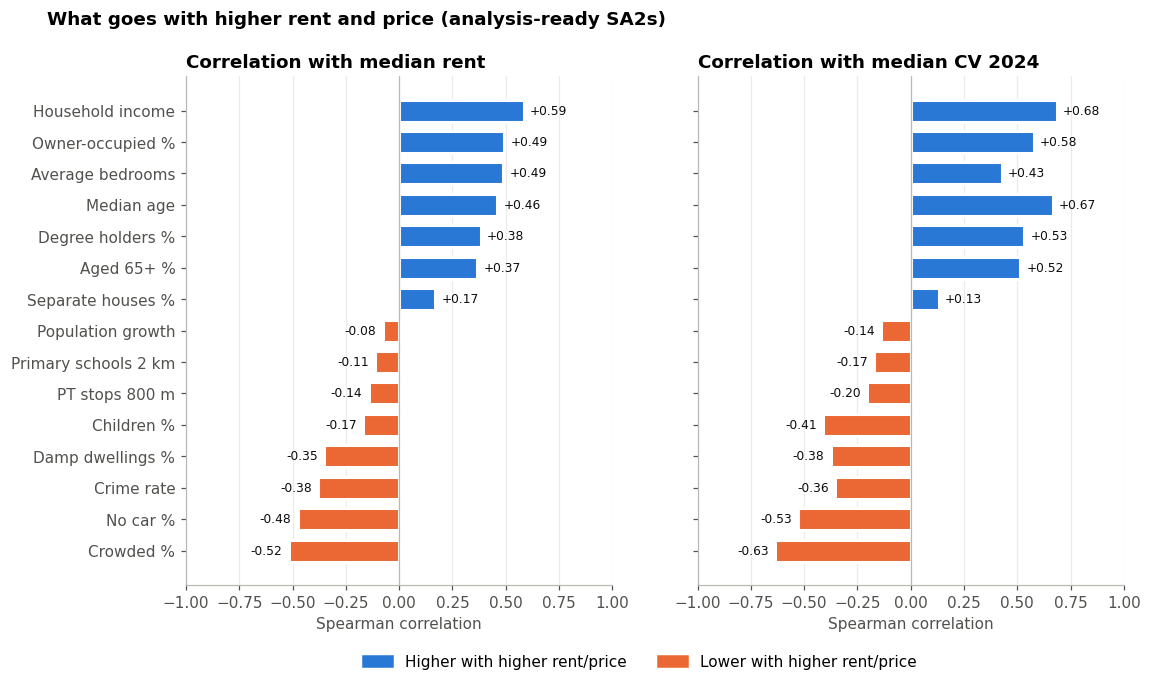

,Rent,CV 2024
Household income,0.59,0.68
Owner-occupied %,0.49,0.58
Average bedrooms,0.49,0.43
Median age,0.46,0.67
Degree holders %,0.38,0.53
Aged 65+ %,0.37,0.52
Separate houses %,0.17,0.13
Population growth,-0.08,-0.14
Primary schools 2 km,-0.11,-0.17
PT stops 800 m,-0.14,-0.20


In [7]:
# STEP 6: SPEARMAN CORRELATION of each area measure with rent and with CV
# (for rent, borrowed-rent duplicates are kept once, so a split parent area doesn't count twice)
drivers = {'median_household_income': 'Household income', 'pct_bachelor_plus': 'Degree holders %',
           'median_age': 'Median age', 'pct_owner_occupied': 'Owner-occupied %', 'pct_separate_house': 'Separate houses %',
           'avg_bedrooms': 'Average bedrooms', 'pct_under_15': 'Children %', 'pct_65_plus': 'Aged 65+ %',
           'pct_crowded': 'Crowded %', 'pct_damp': 'Damp dwellings %', 'pct_no_vehicle': 'No car %',
           'pop_change_2018_2023_pct': 'Population growth', 'primary_schools_2km': 'Primary schools 2 km',
           'pt_stops_800m': 'PT stops 800 m', 'crime_per_1000_residents': 'Crime rate'}
base = ready.dropna(subset=['median_rent_weekly']).drop_duplicates('rent_source_sa2')
nohot = ready[~ready.flag_crime_hotspot]
corr = pd.DataFrame({'Rent': base[list(drivers)].corrwith(base.median_rent_weekly, method='spearman'),
                     'CV 2024': ready[list(drivers)].corrwith(ready.median_cv_2024, method='spearman')})
# crime: hotspots left out, as in File 1
corr.loc['crime_per_1000_residents'] = [base[~base.flag_crime_hotspot].crime_per_1000_residents.corr(base[~base.flag_crime_hotspot].median_rent_weekly, method='spearman'),
                                        nohot.crime_per_1000_residents.corr(nohot.median_cv_2024, method='spearman')]
corr = corr.rename(index=drivers).sort_values('Rent')

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, col in zip(axes, corr.columns):
    ax.barh(corr.index, corr[col], color=np.where(corr[col] > 0, BLUE, ORANGE), height=0.7, edgecolor='white', linewidth=2)
    ax.axvline(0, color=GREY, lw=0.8); ax.set_xlim(-1, 1); ax.grid(axis='y', visible=False)
    ax.set(title=f'Correlation with {"median rent" if col == "Rent" else "median CV 2024"}', xlabel='Spearman correlation')
    for y, v in enumerate(corr[col]):
        ax.annotate(f'{v:+.2f}', (v, y), xytext=(4 if v > 0 else -4, 0), textcoords='offset points',
                    ha='left' if v > 0 else 'right', va='center', fontsize=8, color=INK)
fig.legend(handles=[Patch(color=BLUE, label='Higher with higher rent/price'), Patch(color=ORANGE, label='Lower with higher rent/price')],
           frameon=False, loc='lower center', ncols=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('What goes with higher rent and price (analysis-ready SA2s)', x=0.01, ha='left', fontweight='bold')
fig.savefig(VIZ / '03_rent_price_drivers.png'); plt.show()
corr.round(2).iloc[::-1]

**Reading this:** correlation is not cause. Rent and price go with the same things: income, ownership, age and bedrooms
up, crowding and no-car households down. Every link is weaker for rent than for price, because rent is compressed
(an expensive SA2 does not charge proportionally more rent), which is why yield falls as price rises (File 1).
Schools and transport nearby barely matter (|r| ≤ 0.2): almost every urban SA2 has some.

### Step 7: Area types (clustering)

In [8]:
# STEP 7: AREA TYPES with k-means. Features are standardised (each scaled to mean 0, sd 1) so no single unit dominates.
import os; os.environ.setdefault('LOKY_MAX_CPU_COUNT', '4')   # silences a Windows joblib warning
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

feat = ['log_cv', 'median_household_income', 'median_age', 'pct_owner_occupied', 'pct_separate_house',
        'pct_crowded', 'pct_under_15', 'pct_bachelor_plus', 'log_stop_density', 'pct_one_person']
m['log_cv'] = np.log(m.median_cv_2024)                              # CV is skewed, so log it
m['log_stop_density'] = np.log1p(m.pt_stops / m.land_area_sq_km)    # stops per km², logged
d = m[m.analysis_ready].dropna(subset=feat)
X = StandardScaler().fit_transform(d[feat])
for k in range(3, 9):
    print(f'k={k}: silhouette {silhouette_score(X, KMeans(k, n_init=20, random_state=0).fit_predict(X)):.3f}')

k=3: silhouette 0.310
k=4: silhouette 0.280


k=5: silhouette 0.238
k=6: silhouette 0.247


k=7: silhouette 0.242
k=8: silhouette 0.229


The silhouette score (how cleanly the groups separate, from −1 to 1) is low at every k: Auckland's areas shade into each other
rather than falling into neat types. k = 3 scores best but only splits apartments / cheaper / dearer. **k = 6 is used**
because its groups are recognisable and useful on the dashboard ("areas like this one"). Treat the types as labels, not hard boundaries.

In [9]:
km = KMeans(6, n_init=20, random_state=0).fit(X)
d = d.assign(cluster=km.labels_)
prof = d.groupby('cluster')[feat[1:] + ['median_cv_2024', 'median_rent_weekly']].median()
prof['SA2s'] = d.cluster.value_counts()

# Name each cluster from its profile by rule, not by cluster number (k-means numbers are arbitrary)
names, left = {}, list(prof.index)
def take(idx, name):
    names[idx] = name; left.remove(idx)
take(prof.loc[left, 'pct_separate_house'].idxmin(), 'Apartments & inner city')
take(prof.loc[left, 'pct_crowded'].idxmax(), 'Crowded family suburbs')
take(prof.loc[left, 'median_age'].idxmax(), 'Older & coastal')
take(prof.loc[left, 'median_cv_2024'].idxmax(), 'Affluent established suburbs')
take(prof.loc[left, 'pct_owner_occupied'].idxmax(), 'Outer suburbs & lifestyle blocks')
take(left[0], 'Middle suburbs')
d['area_type'] = d.cluster.map(names)
m = m.merge(d[['sa2_code', 'area_type']], on='sa2_code', how='left')
order = ['Apartments & inner city', 'Affluent established suburbs', 'Middle suburbs', 'Outer suburbs & lifestyle blocks',
         'Crowded family suburbs', 'Older & coastal']
prof.rename(index=names).loc[order].round(1).T

cluster,Apartments & inner city,Affluent established suburbs,Middle suburbs,Outer suburbs & lifestyle blocks,Crowded family suburbs,Older & coastal
median_household_income,83700.0,141000.0,113900.0,138450.0,99250.0,92200.0
median_age,32.5,39.8,35.3,40.0,30.4,45.5
pct_owner_occupied,27.0,65.6,55.9,76.1,40.3,75.3
pct_separate_house,4.4,66.8,77.2,91.2,81.6,83.9
pct_crowded,8.4,4.3,9.3,3.8,22.6,3.7
pct_under_15,6.1,16.6,19.5,19.0,24.6,16.4
pct_bachelor_plus,47.6,48.8,32.2,32.5,15.8,27.4
log_stop_density,3.2,2.6,2.5,1.2,2.7,1.5
pct_one_person,37.4,19.6,16.5,12.3,12.7,25.2
median_cv_2024,490000.0,1675000.0,1000000.0,1360000.0,810000.0,1125000.0


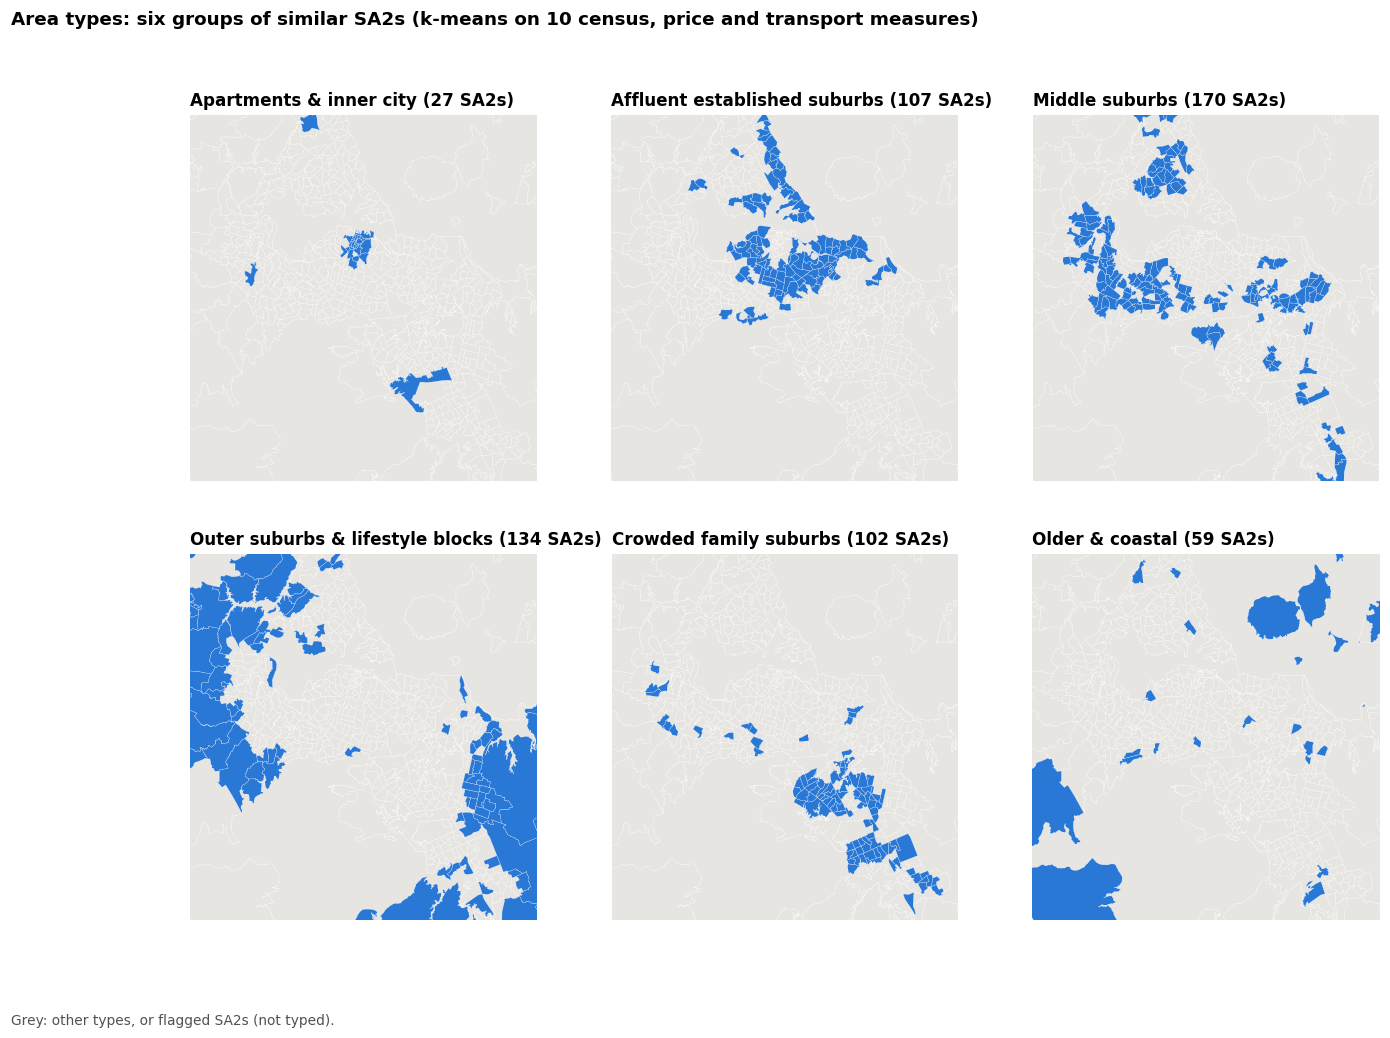

Apartments & inner city: Parnell West, Eden Terrace, Mount Eden North, Symonds Street West, Victoria Park
Affluent established suburbs: Hobsonville Point Park, Narrow Neck, Hauraki, Saint Heliers South, Waiake
Middle suburbs: Glen Innes East-Wai O Taiki Bay, Henderson East, Avondale South (Auckland), Glen Innes West, Takanini South
Outer suburbs & lifestyle blocks: Whenuapai, Kumeū-Huapai North, Te Puru, Ormiston Central, Somerville
Crowded family suburbs: Pukekohe West, Rosehill, Rowandale East, Papatoetoe West, Harania North
Older & coastal: Orewa North, Red Beach East, Warkworth East, Cape Rodney, Snells Beach


In [10]:
gm = geo[['sa2_code', 'geometry']].merge(m, on='sa2_code')
fig, axes = plt.subplots(2, 3, figsize=(14, 9.5))
for ax, t in zip(axes.flat, order):   # small multiples: six types is too many hues for one map
    gm.plot(ax=ax, color='#e6e5e1', edgecolor='white', linewidth=0.15)
    gm[gm.area_type == t].plot(ax=ax, color=BLUE, edgecolor='white', linewidth=0.15)
    ax.set_title(f'{t} ({(m.area_type == t).sum()} SA2s)', fontsize=11); ax.set_axis_off()
    ax.set_xlim(174.55, 175.0); ax.set_ylim(-37.1, -36.72)
fig.suptitle('Area types: six groups of similar SA2s (k-means on 10 census, price and transport measures)', x=0.01, ha='left', fontweight='bold')
fig.text(0.01, 0.01, 'Grey: other types, or flagged SA2s (not typed).', color=MUTED, fontsize=9)
fig.savefig(VIZ / '03_area_types.png'); plt.show()
for t in order:
    ex = m[m.area_type == t].nlargest(5, 'population_2023').sa2_name
    print(f'{t}: {", ".join(ex)}')

### Step 8: Example screen, a family shortlist

In [11]:
# STEP 8: SCREEN. This is the shape of the dashboard's filter page: hard filters, then sort by what matters most.
# Example: a Muslim family renting a 3-bedroom house for $580/week or less.
# The budget caps the rent of the home asked for (dwelling type x bedrooms, File 2's rent_by_type_sa2.csv), not the
# all-dwelling median. SA2s with no published rent for that home are reported separately, never silently dropped.
by_type = pd.read_csv(CLEAN / 'rent_by_type_sa2.csv', dtype={'beds': str})

def shortlist(max_rent=580, dwelling='House', beds='3', community='pct_muslim', n=10):
    r = by_type[(by_type.dwelling == dwelling) & (by_type.beds == beds)][
        ['sa2_code', 'rent', 'quarters', 'rent_min_quarter', 'rent_max_quarter', 'lodged_bonds_4q', 'active_bonds',
         'flag_thin_sample', 'flag_unstable_rent']].rename(columns={'quarters': 'rent_quarters', 'active_bonds': 'active_bonds_type'})
    s = m[m.analysis_ready & ~m.flag_crime_hotspot & (m.area_type != 'Apartments & inner city')].merge(r, on='sa2_code', how='left')
    s['community_people'] = (s[community] / 100 * s.population_2023).round(-1)
    # An estimate failing File 2's sample checks is 'verify', not a budget match, until checked against another source
    s['check'] = np.where(s.rent.isna(), 'no estimate',
                          np.where(s.flag_thin_sample.eq(True) | s.flag_unstable_rent.eq(True), 'verify', 'ok'))
    cols = ['sa2_name', 'area_type', community, 'community_people', 'rent', 'rent_min_quarter', 'rent_max_quarter', 'rent_quarters',
            'lodged_bonds_4q', 'active_bonds_type', 'check', 'median_rent_weekly', 'crime_per_1000_residents',
            'primary_schools_2km', 'year1_schools_in_area', 'km_to_al_madinah_coed', 'km_to_zayed_college_girls', 'mosques_in_area', 'nearest_mosque', 'km_to_nearest_mosque', 'gp_clinics_in_area', 'km_to_nearest_gp_clinic',
            'halal_butchers_in_area', 'km_to_nearest_halal_butcher', 'halal_places_in_area', 'pt_stops_800m', 'pct_crowded', 'rent_source_sa2']
    under, missing = s[s.rent <= max_rent], s[s.rent.isna()]
    confirmed = under[under.check == 'ok']
    print(f'{beds}-bed {dwelling.lower()} at ${max_rent}/wk or less: {len(s)} SA2s pass the other filters | '
          f'{s.rent.notna().sum()} have a rent estimate | {len(under)} under budget on the published figures '
          f'({under.rent_source_sa2.nunique()} distinct MBIE rent areas) | {len(confirmed)} pass the sample checks | '
          f'{len(under) - len(confirmed)} need verification | {len(missing)} have no estimate')
    if beds == '1': print('Note:', by_type.data_note[by_type.beds == '1'].iloc[0])
    return (under.sort_values(community, ascending=False)[cols].head(n),
            s[s.check == 'ok'].nsmallest(n, 'rent')[cols],
            missing.sort_values(community, ascending=False)[cols].head(n))

print(f'Auckland Muslim share: {wavg("pct_muslim"):.1f}%')
qualify, cheapest, no_estimate = shortlist()
print('Under budget on the published figures (see the check column):' if len(qualify) else 'No SA2 is under budget.')
qualify.round(1)

Auckland Muslim share: 2.9%
3-bed house at $580/wk or less: 567 SA2s pass the other filters | 429 have a rent estimate | 4 under budget on the published figures (2 distinct MBIE rent areas) | 0 pass the sample checks | 4 need verification | 138 have no estimate
Under budget on the published figures (see the check column):


,sa2_name,area_type,pct_muslim,community_people,rent,rent_min_quarter,rent_max_quarter,rent_quarters,lodged_bonds_4q,active_bonds_type,check,median_rent_weekly,crime_per_1000_residents,primary_schools_2km,year1_schools_in_area,km_to_al_madinah_coed,km_to_zayed_college_girls,mosques_in_area,nearest_mosque,km_to_nearest_mosque,gp_clinics_in_area,km_to_nearest_gp_clinic,halal_butchers_in_area,km_to_nearest_halal_butcher,halal_places_in_area,pt_stops_800m,pct_crowded,rent_source_sa2
311,Point England North,Crowded family suburbs,4.2,110.0,507.2,166.0,713.0,4.0,30.0,351.0,verify,534.8,36.2,9,1,12.3,12.6,0,Islamic Ahlulbayt Foundation of New Zealand,4.8,0,0.8,0,7.6,0,28,24.2,146300
531,Point England South,Crowded family suburbs,3.4,70.0,507.2,166.0,713.0,4.0,30.0,351.0,verify,534.8,44.2,12,1,11.8,12.0,0,Islamic Ahlulbayt Foundation of New Zealand,4.5,0,1.1,0,7.0,0,27,22.5,146300
498,Tamaki West,Crowded family suburbs,3.0,80.0,422.8,180.0,660.0,4.0,51.0,357.0,verify,580.0,37.4,9,0,10.9,11.2,0,Islamic Ahlulbayt Foundation of New Zealand,4.3,0,0.8,0,6.2,0,26,20.5,147000
476,Tamaki East,Middle suburbs,2.9,50.0,422.8,180.0,660.0,4.0,51.0,357.0,verify,580.0,48.9,10,1,11.0,11.2,0,Islamic Ahlulbayt Foundation of New Zealand,3.7,0,0.8,0,6.0,0,16,16.0,147000


In [12]:
# The evidence behind each under-budget estimate, quarter by quarter: the published median, NEW bonds lodged (the sample
# behind that median) and active bonds (all tenancies held, not the sample). MBIE rounds counts to base 3.
raw = pd.read_csv('data/rental/mbie_quarterly_sa2_2020_2026.csv', dtype=str,
                  usecols=['TimeFrame', 'Location Id', 'Dwelling Type', 'Number Of Beds', 'Median Rent', 'Total Bonds', 'Active Bonds'])
raw = raw[(raw['Dwelling Type'] == 'House') & (raw['Number Of Beds'] == '3')]
raw = pd.DataFrame({'quarter': pd.to_datetime(raw.TimeFrame, dayfirst=True),
                    'rent_source_sa2': pd.to_numeric(raw['Location Id'], errors='coerce'),
                    'median_rent': pd.to_numeric(raw['Median Rent'], errors='coerce'),
                    'new_bonds_lodged': pd.to_numeric(raw['Total Bonds'], errors='coerce'),
                    'active_bonds': pd.to_numeric(raw['Active Bonds'], errors='coerce')})
areas = qualify.groupby('rent_source_sa2').sa2_name.agg(' / '.join)
detail = raw[raw.rent_source_sa2.isin(areas.index) & (raw.quarter > raw.quarter.max() - pd.DateOffset(years=1))]
detail = detail.assign(area=detail.rent_source_sa2.map(areas)).sort_values(['area', 'quarter'])
check_mean = detail.groupby('rent_source_sa2').median_rent.mean()
assert np.allclose(check_mean, qualify.groupby('rent_source_sa2').rent.first().loc[check_mean.index])   # same as the screen
detail.set_index(['area', detail.quarter.dt.strftime('%b %Y')])[['median_rent', 'new_bonds_lodged', 'active_bonds']]

median_rent  new_bonds_lodged  active_bonds
area                                      quarter                                              
Point England North / Point England South Oct 2025        166.0                 6           357
                                          Jan 2026        650.0                 9           354
                                          Apr 2026        713.0                 9           354
                                          Jul 2026        500.0                 6           351
Tamaki West / Tamaki East                 Oct 2025        180.0                12           363
                                          Jan 2026        660.0                12           360
                                          Apr 2026        640.0                12           354
                                          Jul 2026        211.0                15           357

**Reading this:** the budget caps the rent of the home asked for: a **3-bedroom house** (`rent`, mean of the last 4
quarterly MBIE medians for that dwelling type and bedroom count). `lodged_bonds_4q` is the number of **new** bonds lodged
over those quarters, the sample behind the medians; `active_bonds_type` counts all tenancies held and is not the sample.
- Of 567 SA2s that pass the other filters, 429 have a 3-bed house estimate and 4 are under \$580 on the published figures:
  Point England North and South (\$507) and Tamaki West and East (\$423). They rest on **2 rent areas**, because each pair
  shares one MBIE source SA2.
- **No SA2 is a confirmed budget match.** Both rent areas fail the stability check, so all four are marked `verify`:
  - Point England: quarterly medians of \$166, \$650, \$713 and \$500, from 6–9 new lodgements a quarter (30 in all,
    against 351 active bonds).
  - Tāmaki: \$180, \$660, \$640 and \$211, from 12–15 new lodgements a quarter (51 in all, against 357 active bonds).
  - The averages (\$507, \$423) mix two very low quarters with near-market ones. The data cannot say what the low
    quarters are (a few income-related or mis-recorded bonds would be enough).
  - Barfoot & Thompson's August 2026 suburb report gives \$693/wk for a 3-bed in Point England (quoted in the review; a
    different sample, not checked here).
- **Before calling either a match**, check it against Tenancy Services' six-month
  [market rent tool](https://www.tenancy.govt.nz/rent-bond-and-bills/market-rent/) for 3-bed houses, or current whole-house
  listings.
- The next table lists the cheapest 3-bed house estimates that pass both checks: the budget this data can support.
- Their Muslim share (3–4%) is close to Auckland's 2.9%, so this budget doesn't reach the higher-share areas.
- **138 SA2s have no 3-bed house estimate** (too few bonds to publish). They are neither in nor out; `no_estimate` lists them.
- **Correction:** the 15 November shortlist (Aorere North, Ōtāhuhu East, Kelston North, Ōtāhuhu South West, Ōtāhuhu South)
  filtered on the *all-dwelling* median. On 3-bed house rent, four of those cost \$628–698 and Aorere North has no estimate,
  so none of them meets a \$580 budget for a 3-bed house.

The screen ranks on community share only; crime, schools (including the two Islamic school distances), the nearest mosque, transport and crowding are
shown so the person can weigh them,
not folded into one score.

In [13]:
print('Cheapest 3-bed house estimates that pass both sample checks:')
cheapest.round(1)

Cheapest 3-bed house estimates that pass both sample checks:


,sa2_name,area_type,pct_muslim,community_people,rent,rent_min_quarter,rent_max_quarter,rent_quarters,lodged_bonds_4q,active_bonds_type,check,median_rent_weekly,crime_per_1000_residents,primary_schools_2km,year1_schools_in_area,km_to_al_madinah_coed,km_to_zayed_college_girls,mosques_in_area,nearest_mosque,km_to_nearest_mosque,gp_clinics_in_area,km_to_nearest_gp_clinic,halal_butchers_in_area,km_to_nearest_halal_butcher,halal_places_in_area,pt_stops_800m,pct_crowded,rent_source_sa2
202,Pukekohe West,Crowded family suburbs,0.9,40.0,607.5,600.0,620.0,4.0,87.0,273.0,ok,626.2,37.9,5,0,26.1,25.8,0,Al-Mustafa Jamia Masjid (South Auckland Mosque),27.6,0,1.0,0,23.4,0,12,11.8,165500
286,Pukekohe South West,Middle suburbs,2.2,60.0,607.5,600.0,620.0,4.0,87.0,273.0,ok,626.2,16.9,6,1,26.6,26.4,0,Al-Mustafa Jamia Masjid (South Auckland Mosque),28.2,0,1.5,0,24.1,0,5,7.1,165500
80,Pukekohe North,Middle suburbs,0.6,10.0,611.2,600.0,630.0,4.0,54.0,231.0,ok,598.8,73.8,0,0,24.1,23.8,0,Al-Mustafa Jamia Masjid (South Auckland Mosque),25.4,0,2.4,0,21.2,0,3,6.7,165300
340,Pukekohe North West,Crowded family suburbs,2.6,80.0,611.2,600.0,630.0,4.0,54.0,231.0,ok,598.8,42.8,6,2,25.8,25.6,0,Al-Mustafa Jamia Masjid (South Auckland Mosque),27.2,0,0.7,0,22.9,0,16,16.0,165300
277,Rānui North,Crowded family suburbs,4.0,150.0,613.2,580.0,638.0,4.0,33.0,204.0,ok,600.0,40.7,7,1,21.3,21.5,1,Masjid Al-Rahman / West Auckland Mosque (NZMA Ranui),0.4,1,0.5,0,2.4,0,17,15.8,123000
345,Rānui Domain,Crowded family suburbs,4.4,160.0,627.5,600.0,650.0,4.0,36.0,192.0,ok,613.8,59.6,8,1,20.9,21.1,0,Masjid Al-Rahman / West Auckland Mosque (NZMA Ranui),0.3,0,0.2,0,2.6,0,34,15.5,123800
115,Glen Eden North,Middle suburbs,6.7,180.0,638.8,600.0,660.0,4.0,42.0,195.0,ok,595.8,69.2,8,1,15.2,15.3,0,Avondale Islamic Centre (NZMA),4.8,0,0.8,0,2.1,0,13,12.3,129100
244,Sunnyvale East,Middle suburbs,3.3,120.0,638.8,600.0,660.0,4.0,42.0,195.0,ok,595.8,44.1,10,0,16.2,16.3,0,Masjid Al-Rahman / West Auckland Mosque (NZMA Ranui),5.2,0,1.4,0,1.1,0,22,10.1,129100
250,Te Atatū Peninsula North West,Middle suburbs,1.8,70.0,638.8,625.0,655.0,4.0,48.0,150.0,ok,612.5,32.3,4,1,20.6,20.8,0,Masjid Al-Rahman / West Auckland Mosque (NZMA Ranui),5.1,0,2.0,0,2.9,0,11,7.8,123200
316,Te Atatū South-Central,Middle suburbs,2.7,90.0,640.0,585.0,690.0,4.0,33.0,171.0,ok,576.2,29.3,16,0,17.7,17.9,0,Masjid Al-Rahman / West Auckland Mosque (NZMA Ranui),3.8,0,1.0,0,1.2,0,24,7.1,127700


### Step 9: Save outputs

In [14]:
# STEP 9: SAVE
keep = ['sa2_code', 'sa2_name', 'area_type', 'population_2018', 'population_2023', *census,
        'pct_european', 'pct_maori', 'pct_pacific', 'pct_asian', 'primary_schools_2km', 'secondary_schools_3km',
        'km_to_al_madinah_coed', 'km_to_zayed_college_girls', 'km_to_nearest_mosque', 'nearest_mosque', 'pt_stops_800m',
        'primary_schools_in_area', 'secondary_schools_in_area', 'year1_schools_in_area', 'mosques_in_area', 'nearest_primary_school',
        'km_to_nearest_primary_school', 'nearest_secondary_school', 'km_to_nearest_secondary_school',
        'nearest_year1_school', 'km_to_nearest_year1_school', 'nearest_year1_school_authority', 'nearest_year1_school_enrolment_scheme',
        'gp_clinics_in_area', 'nearest_gp_clinic', 'km_to_nearest_gp_clinic',
        'halal_butchers_in_area', 'nearest_halal_butcher', 'km_to_nearest_halal_butcher', 'halal_places_in_area',
        'playgrounds_in_area', 'nearest_playground', 'km_to_nearest_playground', 'parks_in_area', 'nearest_park', 'km_to_nearest_park', 'analysis_ready']
out = CLEAN / 'area_profiles_by_sa2.csv'
m[keep].round(2).to_csv(out, index=False)
check = pd.read_csv(out)
assert len(check) == 633 and check.sa2_code.is_unique and check.area_type.notna().sum() == len(d)
print(f'Saved {out} ({check.shape[0]} rows, {check.shape[1]} columns)')
print('Charts:', ', '.join(sorted(p.name for p in VIZ.glob('03_*.png'))))

Saved data\clean\area_profiles_by_sa2.csv (633 rows, 58 columns)
Charts: 03_area_types.png, 03_life_stage_maps.png, 03_population_change.png, 03_rent_price_drivers.png


# File 3: Area Profiles - Summary

## What we did
Added 16 census measures to `build_master.py` (age, religion, qualifications, crowding, household type, cars, dwelling type,
bedrooms, dampness, population change), counted schools and transport stops near each SA2, measured the distance to the nearest mosque, linked all of it to rent and
price, grouped SA2s into six area types, and built an example screen. Output: `data/clean/area_profiles_by_sa2.csv`.

## Checks
- After the `build_master.py` change, every existing column of `master_dataset_by_sa2.csv`, `master_flagged.csv` and
  `rent_metrics_by_sa2.csv` is identical to before (Files 1 and 2 re-run and compared).
- Population change is left blank where an SA2 had 0 residents in 2018 (it was dividing by zero).
- **Correction:** METHODOLOGY.md gave Auckland's Muslim share as 0.85%. It is **2.9%** (48,108 of 1,656,405).
- **Correction (review, 17 Nov):** the 15 November \$580 shortlist filtered on all-dwelling rent. Filtering on 3-bed house
  rent, as a family budget implies, 4 SA2s are under \$580 on the published figures (2 rent areas: Point England, Tāmaki) and
  138 have no estimate. Both rent areas fail the stability check (quarterly medians swinging between about \$170 and \$700 on
  6–15 new lodgements a quarter), so **no SA2 is a confirmed match**; the cheapest estimates that pass both checks start
  at about \$608 (Pukekohe) (Step 8).

## Key findings
1. **Growth is on the edges.** Auckland +5.4% from 2018 to 2023, almost all in new subdivisions; 243 of 599 SA2s shrank, the inner city most.
2. **Two Aucklands for families.** Children and crowding are concentrated in the south (Ōtara, Māngere, Manurewa, Papakura):
   40 SA2s have more than 25% of households crowded (up to 42% in Rongomai West and Ferguson) against 9.8% Auckland-wide. Older residents cluster on the coast (Orewa, Waiheke, the Hibiscus Coast).
3. **Communities are concentrated.** Muslim (2.9% of Auckland), Hindu (5.5%) and Pacific (16.6%) residents have 61, 79 and 82 SA2s respectively
   at twice the Auckland share, mostly in Mount Roskill, Māngere, Ōtāhuhu and Papatoetoe.
4. **Rent and price follow the same social gradient** (income +0.59/+0.68, crowding −0.52/−0.63), weaker for rent.
   Schools and transport nearby hardly separate areas.
5. **Six area types**, useful as labels but not sharp (silhouette 0.25): apartments & inner city (27), affluent established
   suburbs (107), middle suburbs (170), outer suburbs & lifestyle blocks (134), crowded family suburbs (102), older & coastal (59).

## What this means for the dashboard
- An area page: population trend, life stage, community shares *and head counts*, schools and stops nearby, area type and "similar areas".
- A screen page like Step 8: hard filters (rent for the chosen dwelling type and bedrooms, crime, type), sort by one chosen
  measure, show the rest as columns, and list SA2s with no rent estimate for that home separately.
  Show new lodgements and the quarterly medians next to each rent, and mark thin or unstable estimates `verify`.
- Show 3-bed house rent alongside the all-dwelling median wherever families are the audience.

## Limitations
- Census is March 2023 and randomly rounded to base 3; small SA2s are noisy.
- Amenity counts use the SA2 centre point and ignore service frequency and school zones.
- No data on temples or churches; GP practices and halal food are from OpenStreetMap and incomplete; community presence is from census shares. Facility measures are limited to
  `km_to_nearest_mosque` (with `nearest_mosque`) from the 6 verified entries of a user-supplied list of 14 (18 Nov 2026; far from complete,
  straight-line distance) and two Islamic state-integrated schools
  from the MoE directory, kept separate because they serve different children:
  `km_to_al_madinah_coed` (Al-Madinah School, composite, co-educational) and `km_to_zayed_college_girls` (Zayed College for
  Girls, Years 7–15, girls only). Both are on Westney Road, Māngere, so the two distances are almost the same; together they
  measure distance to Māngere.
- k-means types depend on the chosen features and k; they are descriptive, not a finding.

## Next
- **File 4: Risk & value screen**: combine `master_flagged.csv`, `rent_metrics_by_sa2.csv` and `area_profiles_by_sa2.csv`.